# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [1]:
import pandas as pd

# 1. Lire le fichier
brut = pd.read_csv("donnees/consommation_brut.csv")

# 2. Afficher sa forme (lignes, colonnes)
print("--- Forme du fichier ---")
print(brut.shape)

# 3. Afficher le type de chaque colonne
print("\n--- Types des colonnes ---")
print(brut.dtypes)

# 4. Afficher le nombre de valeurs manquantes par colonne
print("\n--- Valeurs manquantes ---")
print(brut.isna().sum())

# 5. Compter le nombre de lignes en double
print("\n--- Lignes en double ---")
print(brut.duplicated().sum())

--- Forme du fichier ---
(300, 4)

--- Types des colonnes ---
mois                  str
quartier              str
kwh                   str
heures_courant    float64
dtype: object

--- Valeurs manquantes ---
mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64

--- Lignes en double ---
12


**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [2]:
print(f"{brut['quartier'].nunique()} écritures")

43 écritures


**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [3]:
valeurs_incorrectes = brut[pd.to_numeric(brut["kwh"], errors="coerce").isna() & brut["kwh"].notna()]
for valeur in valeurs_incorrectes["kwh"]:
    print(valeur)

184410 kWh
206280 kWh
215140 kWh
251 900
274520 kWh
301740 kWh
233010 kWh
155930 kWh
212510 kWh
424110 kWh
299610 kWh
373 880
333670 kWh
597730 kWh
456060 kWh
495020 kWh
409 300
556 070
260360 kWh
260360 kWh
347870 kWh
408 780
364 090
243160 kWh
154 720
154 720
233 700
253 300
385840 kWh
445270 kWh
337 810
366 390
154 740
170420 kWh
201690 kWh
201690 kWh
81370 kWh
139470 kWh
77670 kWh
139230 kWh
139230 kWh
121 240
160110 kWh
105 830
163010 kWh
198720 kWh
281 240
104 640
166700 kWh
73 110
171 160
187230 kWh


## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [4]:
# On fait une copie propre
propre = brut.copy()

# On nettoie le texte : enlever "kWh", les espaces, et convertir en nombre
propre["kwh"] = propre["kwh"].astype(str).str.replace("kWh", "", regex=False)
propre["kwh"] = propre["kwh"].str.replace(" ", "", regex=False)
propre["kwh"] = pd.to_numeric(propre["kwh"], errors="coerce")

print("Valeurs manquantes :", propre["kwh"].isna().sum())

Valeurs manquantes : 9


**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [5]:
# Lire le fichier de référence des quartiers
quartiers_ref = pd.read_csv("donnees/quartiers.csv")

# Créer un dictionnaire pour faire correspondre les noms (en minuscules)
# Exemple : "delmas 33" -> "Delmas 33"
dico_quartiers = dict(zip(quartiers_ref["quartier"].str.lower().str.strip(), quartiers_ref["quartier"]))

# Appliquer le dictionnaire sur notre colonne
propre["quartier"] = propre["quartier"].str.lower().str.strip().map(dico_quartiers)

print("Quartiers uniques :", propre["quartier"].nunique())
print("Noms non reconnus :", propre["quartier"].isna().sum())

Quartiers uniques : 12
Noms non reconnus : 0


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [6]:
# 1. Supprimer les doublons
propre = propre.drop_duplicates()

# 2. Supprimer les lignes sans kwh
propre = propre.dropna(subset=["kwh"])

# 3. Remettre l'index à zéro
propre = propre.reset_index(drop=True)

print(propre.shape)

(279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [7]:
# --- ON RECRÉE LES DONNÉES PROPRES DE ZÉRO POUR ÊTRE SÛR ---
propre = brut.copy()
propre["kwh"] = propre["kwh"].astype(str).str.replace("kWh", "", regex=False).str.replace(" ", "", regex=False)
propre["kwh"] = pd.to_numeric(propre["kwh"], errors="coerce")
quartiers_ref = pd.read_csv("donnees/quartiers.csv")
dico_quartiers = dict(zip(quartiers_ref["quartier"].str.lower().str.strip(), quartiers_ref["quartier"]))
propre["quartier"] = propre["quartier"].str.lower().str.strip().map(dico_quartiers)
propre = propre.drop_duplicates()
propre = propre.dropna(subset=["kwh"])
propre = propre.reset_index(drop=True)
# ---------------------------------------------------------

# --- MAINTENANT ON FAIT LA QUESTION 7 ---
# 1. Calculer la médiane par quartier
mediane_par_quartier = propre.groupby("quartier")["kwh"].transform("median")

# 2. Trouver les valeurs aberrantes
masque_aberrant = propre["kwh"] > (3 * mediane_par_quartier)

# 3. Afficher les quartiers (exactement comme demandé)
print("Quartiers corrigés :")
for q in propre.loc[masque_aberrant, "quartier"].unique():
    print("-", q)

# 4. Diviser par 10
propre.loc[masque_aberrant, "kwh"] = propre.loc[masque_aberrant, "kwh"] / 10

# 5. Afficher le max
print("\nMaximum kwh après correction :", propre["kwh"].max())

Quartiers corrigés :
- Delmas 33
- Delmas 75
- Morne Calvaire
- Rue 15

Maximum kwh après correction : 742780.0


**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [8]:
# 1. On charge la référence
reference = pd.read_csv("donnees/consommation.csv")

# 2. On fait la jointure (inner join) pour ne garder que les lignes communes
# (Cela va retirer les lignes de la référence qui sont des doublons ou des valeurs manquantes)
comparaison = propre.merge(
    reference, 
    on=["mois", "quartier"], 
    suffixes=("_toi", "_ref")
)

# 3. On vérifie que les valeurs de kwh et heures_courant sont identiques
# On arrondit pour éviter les problèmes de décimales
kwh_ok = (comparaison["kwh_toi"].round() == comparaison["kwh_ref"].round()).all()
heures_ok = (comparaison["heures_courant_toi"].round(1) == comparaison["heures_courant_ref"].round(1)).all()

# 4. La preuve ultime
est_identique = kwh_ok and heures_ok
print(est_identique)

True


## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [9]:
quartiers = pd.read_csv("donnees/quartiers.csv")
propre = propre.merge(quartiers, on="quartier", how="left")

# Calculs
propre["kwh_par_abonne"] = (propre["kwh"] / propre["abonnes"]).round(1)
propre["annee"] = propre["mois"].str[:4]

print("Lignes :", len(propre))

# Vérification (Bas-Peu-de-Chose en 2024-01)
bas = propre[(propre["quartier"] == "Bas-Peu-de-Chose") & (propre["mois"] == "2024-01")]
print(bas[["quartier", "mois", "kwh_par_abonne"]])

Lignes : 279
           quartier     mois  kwh_par_abonne
0  Bas-Peu-de-Chose  2024-01            85.8


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [10]:
meteo = pd.read_csv("donnees/meteo.csv")
propre = propre.merge(meteo, on=["mois", "commune"], how="left")

print("Lignes :", len(propre))
print("Températures manquantes :", propre["temperature_c"].isna().sum())

Lignes : 279
Températures manquantes : 0


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [11]:
propre.to_csv("donnees/consommation_propre.csv", index=False)
print("Fichier sauvegardé !")

# On relit le fichier pour confirmer
test_read = pd.read_csv("donnees/consommation_propre.csv")
print("Forme du fichier final :", test_read.shape)

Fichier sauvegardé !
Forme du fichier final : (279, 11)


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

In [12]:
import matplotlib.pyplot as plt

# 1. Par type
moy_type = propre.groupby("type")["kwh_par_abonne"].mean().round(1)
print("Moyenne par type :")
print(moy_type)

# 2. Classement des 12 quartiers
classement = propre.groupby("quartier")["kwh_par_abonne"].mean().round(1).sort_values(ascending=False)
print("\nClassement des quartiers :")
print(classement)

Moyenne par type :
type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64

Classement des quartiers :
quartier
Centre-ville          468.7
Place Saint-Pierre    458.3
Delmas 33             374.4
Rue 15                268.5
Morne Calvaire        166.1
Thomassin             146.0
Delmas 65             134.9
Bois-Verna            130.1
Delmas 75             118.6
Bas-Peu-de-Chose      100.2
Carénage               72.2
Petite-Anse            69.6
Name: kwh_par_abonne, dtype: float64


**Ce qu'on en conclut :**

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

In [13]:
# 1. Consommation totale par commune et par année
conso_totale = propre.pivot_table(index="commune", columns="annee", values="kwh", aggfunc="sum")

# 2. Calcul de la hausse en % (avant d'arrondir) ET ON TRIE
hausse = ((conso_totale["2025"] - conso_totale["2024"]) / conso_totale["2024"] * 100).round(1).sort_values(ascending=False)

# 3. Passage en millions et arrondi à 2 (on trie aussi pour que ce soit dans le même ordre)
conso_millions = (conso_totale / 1_000_000).round(2).loc[hausse.index]

# Affichage
print("En millions de kWh :")
print(conso_millions)
print("\nHausse en % :")
print(hausse)

En millions de kWh :
annee            2024   2025
commune                     
Cap-Haïtien      4.59   5.62
Pétion-Ville     8.60   9.68
Port-au-Prince  10.09  10.31
Delmas          11.61  11.74

Hausse en % :
commune
Cap-Haïtien       22.5
Pétion-Ville      12.6
Port-au-Prince     2.3
Delmas             1.1
dtype: float64


**Ce qu'on en conclut :**

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

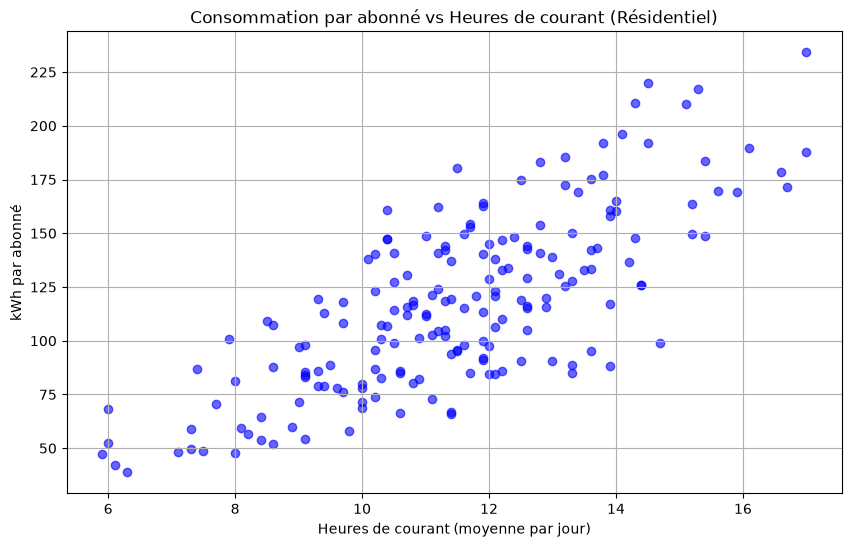

Corrélation avec les heures de courant : 0.76
Corrélation avec la température : -0.15


In [14]:
import matplotlib.pyplot as plt

# On filtre uniquement le résidentiel
resid = propre[propre["type"] == "Résidentiel"]

# 1. Nuage de points
plt.figure(figsize=(10, 6))
plt.scatter(resid["heures_courant"], resid["kwh_par_abonne"], alpha=0.6, color="blue")
plt.title("Consommation par abonné vs Heures de courant (Résidentiel)")
plt.xlabel("Heures de courant (moyenne par jour)")
plt.ylabel("kWh par abonné")
plt.grid(True)
plt.show()

# 2. Corrélations
corr_courant = resid["kwh_par_abonne"].corr(resid["heures_courant"])
corr_temp = resid["kwh_par_abonne"].corr(resid["temperature_c"])

print(f"Corrélation avec les heures de courant : {corr_courant:.2f}")
print(f"Corrélation avec la température : {corr_temp:.2f}")

**Ce qu'on en conclut :**

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

--- Statistiques par commune ---
                mediane    Q1    Q3
commune                            
Cap-Haïtien        10.0   8.3  11.7
Delmas             11.9  10.1  13.0
Port-au-Prince     11.6  10.7  13.1
Pétion-Ville       11.6  10.4  13.0


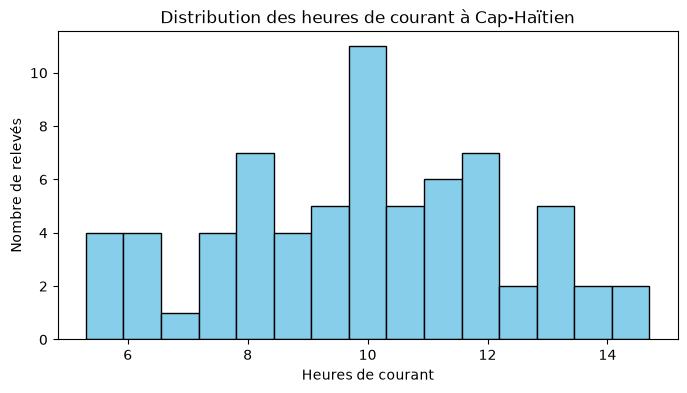


Nombre de relevés < 8h en 2025 : 3
   mois  quartier  heures_courant
2025-01 Delmas 33             7.4
2025-08  Carénage             7.3
2025-11    Rue 15             5.9


In [15]:
import matplotlib.pyplot as plt

# 1. Médiane, Q1, Q3 par commune
stats_communes = propre.groupby("commune")["heures_courant"].agg(
    mediane="median",
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
).round(1)

print("--- Statistiques par commune ---")
print(stats_communes)

# 2. Histogramme pour Cap-Haïtien
cap = propre[propre["commune"] == "Cap-Haïtien"]

plt.figure(figsize=(8, 4))
plt.hist(cap["heures_courant"], bins=15, color="skyblue", edgecolor="black")
plt.title("Distribution des heures de courant à Cap-Haïtien")
plt.xlabel("Heures de courant")
plt.ylabel("Nombre de relevés")
plt.show()

# 3. Relevés de 2025 avec moins de 8h
moins_8h = propre[(propre["annee"] == "2025") & (propre["heures_courant"] < 8)]

print(f"\nNombre de relevés < 8h en 2025 : {len(moins_8h)}")
print(moins_8h[["mois", "quartier", "heures_courant"]].to_string(index=False))

**Ce qu'on en conclut :**

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [16]:
# On cherche les 3 plus grandes valeurs de kwh
top3 = propre.nlargest(3, "kwh")[["mois", "quartier", "type", "kwh"]]

print("--- Top 3 des consommations ---")
print(top3.to_string(index=False))

--- Top 3 des consommations ---
   mois     quartier       type      kwh
2025-07    Delmas 33 Commercial 742780.0
2024-11 Centre-ville Commercial 597730.0
2025-09    Delmas 33 Commercial 591420.0


**Ce qu'on en conclut :**

## 9. Conclusion

En trois phrases, répondez au directeur : la consommation suit-elle la chaleur, ou les heures de courant ? Citez vos chiffres, et dites ce qu'une corrélation ne permet pas de conclure.

La consommation par abonné est fortement corrélée aux heures de courant (0.76), alors qu'elle est très faiblement corrélée à la température (-0.15). 
La consommation suit donc principalement la disponibilité du réseau électrique plutôt que la chaleur. 
Cependant, une corrélation ne permet pas d'établir un lien de causalité direct, d'autres facteurs (comme le type d'équipements ou le niveau de vie) pouvant influencer la consommation.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.